# Frequency response at the center of a square transmitter loop.
## *comparing approaches.*
Matt Griffiths

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from em1d.experiment import Loop, Receiver
from em1d.transforms import Hankel
from em1d.physics import refl_transverse_electric as rte, freespace_u0 as u0

In [3]:
# first lets compute Hz(R)

In [4]:
lp = Loop.square(50)
lp.x += 0.005156154881
rx = Receiver()

In [5]:
rmin = lp.min_horizontal_distance(rx)
rmax = lp.max_horizontal_distance(rx)

In [6]:
def integrand(wave_length):
    sigma = np.array([10, 1., 10])[:,None,None]
    thick = np.array([25, 50])[:,None,None]
    omega = np.array([100.])[None,:,None]*2*np.pi
    lmb = wave_length[None, None, :]
    intg = (1.+rte(sigma, thick, omega, lmb))*lmb**2 / u0(omega, lmb)
    print(intg.shape)
    return intg


hkl = Hankel(integrand, 1)

(1, 1, 1, 1, 1, 1, 1, 301)


C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\repositories\em1d\src\em1d\physics\physics.py:114: RuntimeWarning: overflow encountered in tanh
  tanh_un_thick = np.tanh(adm_intrinsic[:-1]*thickness*zn[:-1])


In [7]:
r, hr = hkl.range(rmin, rmax)

In [8]:
from scipy.interpolate import interp1d

int_hr = interp1d(np.log10(r), hr)

def hr_interp(r):
    return int_hr(np.log10(r))

In [9]:
from em1d.transforms import plot_loglog
from em1d.experiment import getRz

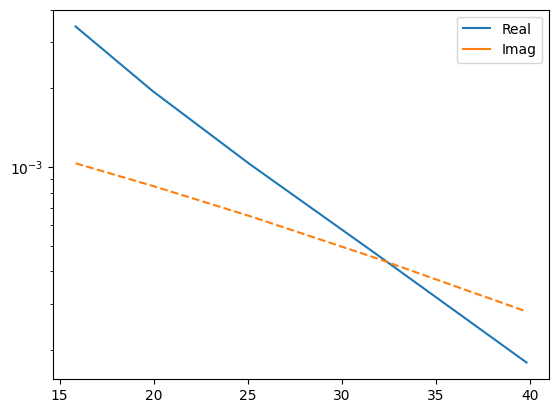

In [10]:
fig,axs = plt.subplots()
axs = plot_loglog(r, hr, ax=axs)
axs.set_xscale('linear')

In [11]:
from numpy.linalg import norm


def integrate_around_loop(lp, rx, hr):
    lp_xyz = lp.xyz - rx.xyz[None, ...]

    HR = 0+0j
    n_dipoles = 0
    for i in range(len(lp)-1):
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = np.einsum('...i,...i->...', Rz, lp_xyz[i])
        p2 = np.einsum('...i,...i->...', Rz, lp_xyz[i+1])

        p12 = p2-p1
        tdist = norm(p12, axis=-1)
        p12 /= tdist
        cp = p1
        cdist = 0

        while cdist < tdist:
            cR = norm(cp)
            ds = cR/15.
            if cdist+ds > tdist:
                ds = tdist-cdist
                cdist += cR/15
            else:
                cdist += ds
            HR += ds*p1[1]*hr(cR)/cR
            cp += ds*p12
            n_dipoles +=1
    return HR

In [12]:
hz_loop = integrate_around_loop(lp, Receiver(), hr_interp)

In [13]:
print(r)
lp = Loop.square(50)
s = lp.s_of_r(Receiver(), r)
print(s)

[15.84893192 19.95262315 25.11886432 31.6227766  39.81071706]
[  0.           0.           0.         -76.93984186   0.        ]


C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\repositories\em1d\src\em1d\experiment\experiment.py:127: RuntimeWarning: invalid value encountered in sqrt
  ds = 2*np.nan_to_num(np.sqrt(R_edge2**2 - r_perp**2) - np.sqrt(R_edge1**2 - r_perp**2))


In [14]:
hz_sr = (hr/r).dot(s+0j)

<Axes: >

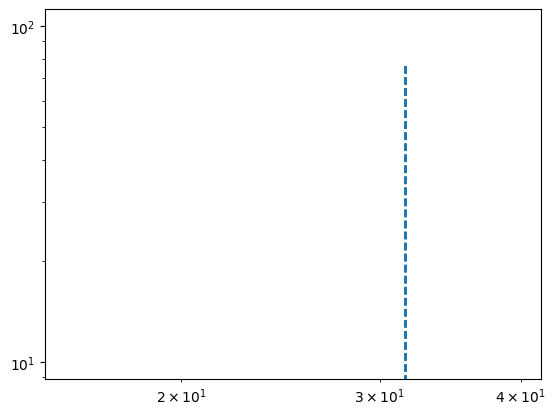

In [15]:
fig,axs=plt.subplots()
# plot_loglog(r, hr*(s+0j) / r, ax=axs)
plot_loglog(r, s, ax=axs)

In [16]:
print(hz_loop)
print(hz_sr)

(-0.1340046122446195+0.09718647877708174j)
(-0.001159191413843492+0.0011046290629078558j)


In [17]:
lp = Loop.square(50)

xy = np.linspace(-100, 100, 51)
HZ2 = np.zeros((len(xy), len(xy)), dtype=complex)

rxall = Receiver(x=xy, y=xy)
rmin = lp.min_horizontal_distance(rxall)
rmax = lp.max_horizontal_distance(rxall)
print(rmin, rmax)
hkl = Hankel(integrand, 1, smp_per_decade=20)
r, hr = hkl.range(rmin, rmax)
int_hr = interp1d(r, hr, kind='nearest')

def hr_interp(r):
    return int_hr(r)


for i in range(len(xy)):
    for j in range(len(xy)):
        rx = Receiver(x=xy[i], y=xy[j])
        hz_loop = integrate_around_loop(lp, rx, hr_interp)
        HZ2[i,j] = hz_loop
    print(f'{i}of{len(xy)}', flush=True, end='\r')

1.0 176.7766952966369
(1, 1, 1, 1, 1, 1, 1, 601)


In [23]:
HZ = np.zeros((len(xy), len(xy)), dtype=complex)

rxall = Receiver(x=xy, y=xy)
rmin = lp.min_horizontal_distance(rxall)
rmax = lp.max_horizontal_distance(rxall)
r, hr = hkl.range(rmin, rmax)

dr = np.gradient(r)

for i in range(len(xy)):
    for j in range(len(xy)):
        rx = Receiver(x=xy[i], y=xy[j])
        s = lp.s_of_r(rx, r)
        s = np.convolve(s, np.array([2, 8, 1])/11, mode='same')+0j
        # hrs = np.convolve(hr*s, np.array([2, 8, 1])/11, mode='same')
        HZ[i,j] = hr.dot(s)

C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\repositories\em1d\src\em1d\experiment\experiment.py:127: RuntimeWarning: invalid value encountered in sqrt
  ds = 2*np.nan_to_num(np.sqrt(R_edge2**2 - r_perp**2) - np.sqrt(R_edge1**2 - r_perp**2))


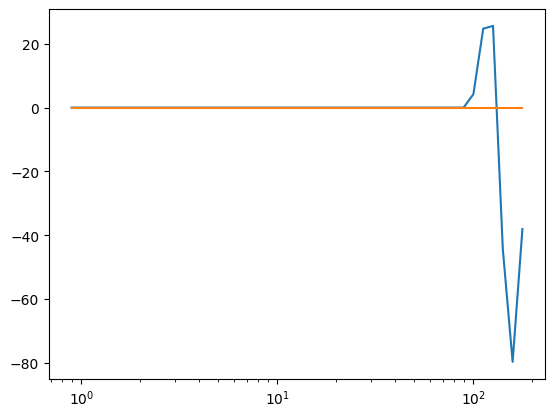

In [24]:
fig,ax = plt.subplots()
# plt.plot(r, s, '.-')
# plt.plot(r, hr.real, '.-')
# plt.plot(r, hr.imag, '.-')
plt.plot(r, (s).real)
plt.plot(r, (s).imag)
plt.xscale('log')

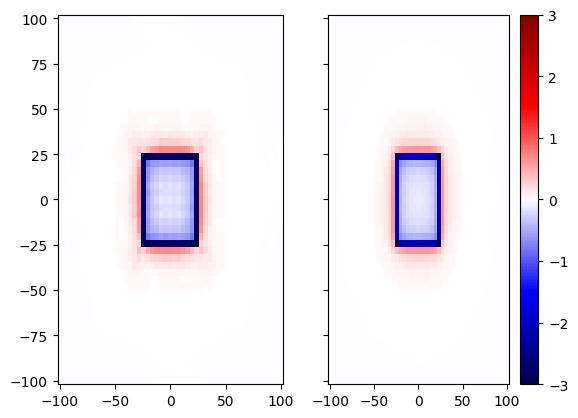

In [25]:
fig,axs = plt.subplots(1,2, sharex=True, sharey=True)
pcm = axs[0].pcolor(xy, xy, HZ.real, vmin=-3, vmax=3, cmap='seismic')
pcm = axs[1].pcolor(xy, xy, HZ2.real, vmin=-3, vmax=3, cmap='seismic')
plt.colorbar(pcm)

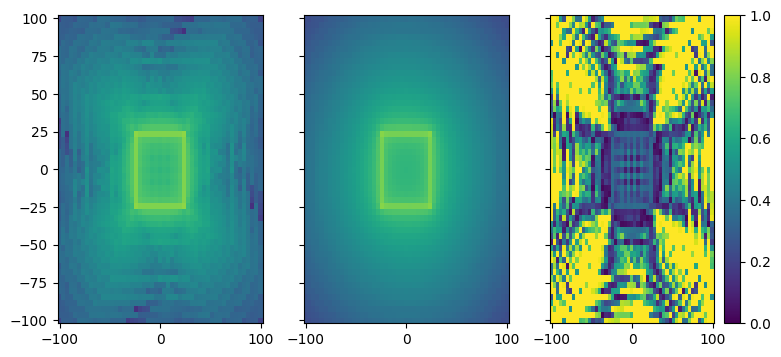

In [26]:
fig,axs = plt.subplots(1,3, sharex=True, sharey=True, figsize=(9,4))
pcm = axs[0].pcolor(xy, xy, np.log10(np.abs(HZ)), vmin=-6, vmax=2)
pcm = axs[1].pcolor(xy, xy, np.log10(np.abs(HZ2)), vmin=-6, vmax=2)
pcm=axs[2].pcolor(xy, xy, np.abs((HZ2-HZ)/HZ2), vmin=0, vmax=1)
plt.colorbar(pcm)

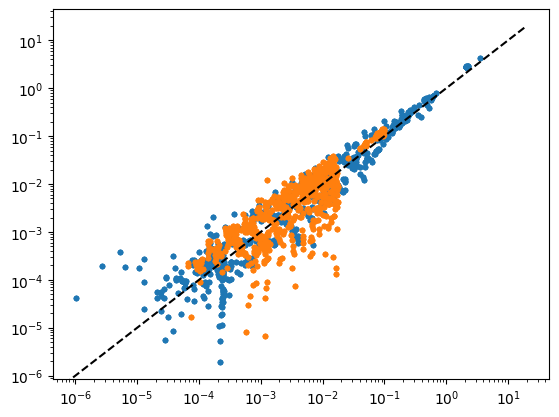

In [27]:
plt.figure()
plt.plot(np.abs(HZ2.flatten().real), np.abs(HZ.flatten().real), '.')
plt.plot(np.abs(HZ2.flatten().imag), np.abs(HZ.flatten().imag), '.')
plt.plot([0,20], [0, 20], 'k--')
plt.yscale('log')
plt.xscale('log')